In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from utils.dataset_lexicon_processing import sanitize_none_string

extracted_examples_df_path = "data/extracted_examples/extracted_examples_lemma_with_pos_mapped.csv"
extracted_examples = pd.read_csv(extracted_examples_df_path)
extracted_examples['sociodemographics_mapped'] = extracted_examples['sociodemographics_mapped'].apply(lambda x: sanitize_none_string(x))

[nltk_data] Downloading package punkt to /home/samuele/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /home/samuele/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to /home/samuele/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /home/samuele/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
/tmp/ipykernel_148461/3541875816.py:6: DtypeWarning: Columns (0: original_label) have mixed types. Specify dtype option on import or set low_memory=False.
  extracted_examples = pd.read_csv(extracted_examples_df_path)


In [2]:
import os
figure_dir = "figures/demographic_pairwise_comparison"
os.makedirs(figure_dir, exist_ok=True)


In [3]:
import numpy as np
import ast
class DatasetProcessor():
    def __init__(self, extracted_examples_df_path, valid_sociodemographic_variables):
        self.extracted_examples_df_path = extracted_examples_df_path
        self.valid_sociodemographic_variables = valid_sociodemographic_variables
        
        self.extracted_examples = pd.read_csv(extracted_examples_df_path, dtype={'original_label': str})

        # Ensure sociodemographics and tags are read as dictionary
        self._postprocess_extracted_examples()
    
    def _postprocess_extracted_examples(self):
        self.extracted_examples['sociodemographics_mapped'] = self.extracted_examples['sociodemographics_mapped'].apply(lambda x: sanitize_none_string(x))
        self.extracted_examples['tag'] = self.extracted_examples['tag'].apply(lambda x: ast.literal_eval(x) if not pd.isna(x) else None)

    # Method to obtain gold label for each text given the specified sociodemographics (either single or multiple) -> Useful both for plotting and for the LMM part later
    def get_gold_label_dataset_based_on_sociodemographics(self, sociodemographics, tie_break_strategy='exclude'):
        """
        sociodemographics: list of sociodemographic attributes to consider
        tie_break_strategy: 'first', 'random', or 'exclude'
        """
        assert all(s in self.valid_sociodemographic_variables for s in sociodemographics)

        def filter_by_sociodemographics(row):
            if row['sociodemographics_mapped'] is None:
                return False
            for soc in sociodemographics:
                if soc not in row['sociodemographics_mapped']:
                    return False
                if row['sociodemographics_mapped'][soc] is None:
                    return False
            return True
        
        filtered_df = self.extracted_examples[self.extracted_examples.apply(filter_by_sociodemographics, axis=1)].copy()

        # Prep for grouping
        filtered_df['sociodemographics_mapped_subset'] = filtered_df['sociodemographics_mapped'].apply(lambda x: str(dict(sorted({soc: x[soc] for soc in sociodemographics}.items()))))
        filtered_df['tag'] = filtered_df['tag'].apply(lambda x: str(sorted(x)) if x is not None else None)

        def resolve_mode(x):
            modes = x.mode()
            if len(modes) == 0:
                return None
            if len(modes) > 1:
                if tie_break_strategy == 'random':
                    return modes.sample(1).values[0]
                elif tie_break_strategy == 'exclude':
                    return np.nan  # We will drop these rows after aggregation
                # Default 'first' behavior
                return modes[0]
            return modes[0]

        # Aggregate using the custom resolver
        output_df = filtered_df.groupby(['text_id', 'lemma_with_pos', 'tag', 'sociodemographics_mapped_subset'])['label'].agg(resolve_mode).reset_index()

        # If strategy was 'exclude', remove the tied rows
        if tie_break_strategy == 'exclude':
            initial_count = len(output_df)
            output_df = output_df.dropna(subset=['label'])
            print(f"Excluded {initial_count - len(output_df)} tied instances ({(initial_count - len(output_df)) / initial_count * 100:.2f}%).")

        # Cleanup and back-conversion
        output_df['sociodemographics_mapped_subset'] = output_df['sociodemographics_mapped_subset'].apply(lambda x: eval(x))
        output_df['tag'] = output_df['tag'].apply(lambda x: set(ast.literal_eval(x)) if not pd.isna(x) else None)
        output_df.rename(columns={'sociodemographics_mapped_subset': 'sociodemographics_mapped'}, inplace=True)
        
        return output_df

In [4]:
valid_sociodemographic_variables = {'age', 'gender', 'education', 'ideology', 'race'}
dprocessor = DatasetProcessor(extracted_examples_df_path, valid_sociodemographic_variables)

In [5]:
age_aggregated_df = dprocessor.get_gold_label_dataset_based_on_sociodemographics(['age'])
race_aggregated_df = dprocessor.get_gold_label_dataset_based_on_sociodemographics(['race'])
gender_aggregated_df = dprocessor.get_gold_label_dataset_based_on_sociodemographics(['gender'])
education_aggregated_df = dprocessor.get_gold_label_dataset_based_on_sociodemographics(['education'])
ideology_aggregated_df = dprocessor.get_gold_label_dataset_based_on_sociodemographics(['ideology'])

Excluded 4845 tied instances (6.57%).
Excluded 3228 tied instances (6.20%).
Excluded 4351 tied instances (7.92%).
Excluded 940 tied instances (8.31%).
Excluded 3545 tied instances (6.24%).


In [6]:
# 'text_id', 'lemma_with_pos', 'tag', 'sociodemographics_mapped_subset'
# Find instances with duplicates on those columns in the original extracted_examples dataframe
# 'text_id', 'lemma_with_pos', 'tag', 'sociodemographics_mapped'
# Find instances with duplicates on those columns in the original extracted_examples dataframe

def make_hashable(x):
    if isinstance(x, dict):
        return tuple(sorted((k, make_hashable(v)) for k, v in x.items()))
    if isinstance(x, set):
        return tuple(sorted(make_hashable(v) for v in x))
    if isinstance(x, list):
        return tuple(make_hashable(v) for v in x)
    return x

tmp = age_aggregated_df.assign(
    tag_hash=age_aggregated_df["tag"].apply(make_hashable),
    sociodemographics_mapped_hash=age_aggregated_df["sociodemographics_mapped"].apply(make_hashable),
)

duplicate_instances = age_aggregated_df[
    tmp.duplicated(
        subset=["text_id", "lemma_with_pos", "tag_hash", "sociodemographics_mapped_hash"],
        keep=False
    )
]

print(f"Number of duplicate instances in the original extracted_examples dataframe: {len(duplicate_instances)}")

Number of duplicate instances in the original extracted_examples dataframe: 0


In [7]:
def preprocess_for_category_pairwise_analysis(aggregated_df):
    """
    Duplicates at tag level appear if a text matches with multiple lemmas with same tag
    """
    aggregated_df = aggregated_df[['text_id', 'tag', 'sociodemographics_mapped', 'label']].explode('tag').reset_index(drop=True)
    # Remove duplicates 
    aggregated_df = aggregated_df.assign(
        sociodemographics_mapped_str=aggregated_df['sociodemographics_mapped'].astype(str)
    )
    
    aggregated_df = aggregated_df.drop_duplicates(
        subset=['text_id', 'tag', 'sociodemographics_mapped_str', 'label']
    ).drop(columns=['sociodemographics_mapped_str']).reset_index(drop=True)
    
    return aggregated_df

In [8]:
def preprocess_for_lemma_pairwise_analysis(aggregated_df):
    aggregated_df = aggregated_df[['text_id', 'lemma_with_pos', 'sociodemographics_mapped', 'label']].reset_index(drop=True)

    # Remove duplicates 
    aggregated_df = aggregated_df.assign(
        sociodemographics_mapped_str=aggregated_df['sociodemographics_mapped'].astype(str)
    )
    print(f"len aggregated_df before dropping duplicates: {len(aggregated_df)}")
    aggregated_df = aggregated_df.drop_duplicates(
        subset=['text_id', 'lemma_with_pos', 'sociodemographics_mapped_str', 'label']
    ).drop(columns=['sociodemographics_mapped_str']).reset_index(drop=True)
    print(f"len aggregated_df after dropping duplicates: {len(aggregated_df)}")
    # print(f"Dropped {len(aggregated_df) - len(aggregated_df.drop_duplicates(subset=['text_id', 'lemma_with_pos', 'sociodemographics_mapped', 'label']))} duplicate instances for lemma pairwise analysis.")

    return aggregated_df

### UNDERSTAND WHY EVEN HERE SOME ARE DROPPED

In [17]:
age_aggregated_df

,text_id,lemma_with_pos,tag,sociodemographics_mapped,label
0,annWithAttitudes_text-0,"('fuck', 'v')",{asm},{'age': '35-44'},not_hurtful
2,annWithAttitudes_text-10,"('can', 'n')","{om, cds}",{'age': '25-34'},not_hurtful
4,annWithAttitudes_text-10,"('can', 'n')","{om, cds}",{'age': '45-54'},not_hurtful
5,annWithAttitudes_text-100,"('head', 'n')",{cds},{'age': '25-34'},not_hurtful
6,annWithAttitudes_text-100,"('head', 'n')",{cds},{'age': '35-44'},not_hurtful
...,...,...,...,...,...
73739,voiced_text-999,"('planet', 'n')",{qas},{'age': '55-64'},hurtful
73740,voiced_text-999,"('waste', 'n')","{qas, cds}",{'age': '25-34'},hurtful
73741,voiced_text-999,"('waste', 'n')","{qas, cds}",{'age': '35-44'},hurtful
73742,voiced_text-999,"('waste', 'n')","{qas, cds}",{'age': '45-54'},hurtful


In [10]:
age_aggregated_df_category = preprocess_for_category_pairwise_analysis(age_aggregated_df)
race_aggregated_df_category = preprocess_for_category_pairwise_analysis(race_aggregated_df)
gender_aggregated_df_category = preprocess_for_category_pairwise_analysis(gender_aggregated_df)
education_aggregated_df_category = preprocess_for_category_pairwise_analysis(education_aggregated_df)
ideology_aggregated_df_category = preprocess_for_category_pairwise_analysis(ideology_aggregated_df)

In [11]:
age_aggregated_df_lemma = preprocess_for_lemma_pairwise_analysis(age_aggregated_df)
race_aggregated_df_lemma = preprocess_for_lemma_pairwise_analysis(race_aggregated_df)
gender_aggregated_df_lemma = preprocess_for_lemma_pairwise_analysis(gender_aggregated_df)
education_aggregated_df_lemma = preprocess_for_lemma_pairwise_analysis(education_aggregated_df)
ideology_aggregated_df_lemma = preprocess_for_lemma_pairwise_analysis(ideology_aggregated_df)


len aggregated_df before dropping duplicates: 68899
len aggregated_df after dropping duplicates: 68899
len aggregated_df before dropping duplicates: 48811
len aggregated_df after dropping duplicates: 48811
len aggregated_df before dropping duplicates: 50588
len aggregated_df after dropping duplicates: 50588
len aggregated_df before dropping duplicates: 10366
len aggregated_df after dropping duplicates: 10366
len aggregated_df before dropping duplicates: 53279
len aggregated_df after dropping duplicates: 53279


In [15]:
age_aggregated_df_category

,text_id,tag,sociodemographics_mapped,label
0,annWithAttitudes_text-0,asm,{'age': '35-44'},not_hurtful
1,annWithAttitudes_text-10,om,{'age': '25-34'},not_hurtful
2,annWithAttitudes_text-10,cds,{'age': '25-34'},not_hurtful
3,annWithAttitudes_text-10,om,{'age': '45-54'},not_hurtful
4,annWithAttitudes_text-10,cds,{'age': '45-54'},not_hurtful
...,...,...,...,...
104978,voiced_text-999,cds,{'age': '55-64'},hurtful
104979,voiced_text-999,qas,{'age': '25-34'},hurtful
104980,voiced_text-999,qas,{'age': '35-44'},hurtful
104981,voiced_text-999,qas,{'age': '45-54'},hurtful


In [16]:
age_aggregated_df_lemma

,text_id,lemma_with_pos,sociodemographics_mapped,label
0,annWithAttitudes_text-0,"('fuck', 'v')",{'age': '35-44'},not_hurtful
1,annWithAttitudes_text-10,"('can', 'n')",{'age': '25-34'},not_hurtful
2,annWithAttitudes_text-10,"('can', 'n')",{'age': '45-54'},not_hurtful
3,annWithAttitudes_text-100,"('head', 'n')",{'age': '25-34'},not_hurtful
4,annWithAttitudes_text-100,"('head', 'n')",{'age': '35-44'},not_hurtful
...,...,...,...,...
68894,voiced_text-999,"('planet', 'n')",{'age': '55-64'},hurtful
68895,voiced_text-999,"('waste', 'n')",{'age': '25-34'},hurtful
68896,voiced_text-999,"('waste', 'n')",{'age': '35-44'},hurtful
68897,voiced_text-999,"('waste', 'n')",{'age': '45-54'},hurtful


In [12]:
from itertools import combinations
import pandas as pd

def calculate_pairwise_tag_weights(df, variable_name, use_lemmas=False):
    df = df.copy()
    df[variable_name] = df['sociodemographics_mapped'].apply(lambda x: x.get(variable_name))
    df = df.dropna(subset=[variable_name])
    
    unique_groups = df[variable_name].unique()
    all_results = {}

    for val1, val2 in combinations(unique_groups, 2):
        comparison_key = f"{val1} vs {val2}"
        group_counts = df.groupby('text_id')[variable_name].apply(set)
        valid_ids = group_counts[group_counts.apply(lambda x: {val1, val2}.issubset(x))].index
        
        if len(valid_ids) == 0:
            continue

        pair_df = df[(df['text_id'].isin(valid_ids)) & (df[variable_name].isin({val1, val2}))]
        exploded_df = pair_df.explode('tag')
        
        tag_data = {}
        unique_tags = exploded_df['tag'].dropna().unique()

        for tag in unique_tags:
            tag_df = exploded_df[exploded_df['tag'] == tag]
            tag_group_counts = tag_df.groupby('text_id')[variable_name].apply(set)
            tag_valid_ids = tag_group_counts[tag_group_counts.apply(lambda x: {val1, val2}.issubset(x))].index
            
            tag_specific_df = tag_df[tag_df['text_id'].isin(tag_valid_ids)]
            n_texts_for_tag = len(tag_valid_ids)

            if n_texts_for_tag > 0:
                # Pivot local data to easily compare A and B for the same text_id
                # This ensures we are looking at the exact same instances
                comparison_pivot = tag_specific_df.pivot(index='text_id', columns=variable_name, values='label')
                
                # Instance where Group A says hurtful, but Group B says not_hurtful
                a_more_sensitive = ((comparison_pivot[val1] == 'hurtful') & 
                                    (comparison_pivot[val2] == 'not_hurtful')).sum()
                
                # Instance where Group B says hurtful, but Group A says not_hurtful
                b_more_sensitive = ((comparison_pivot[val2] == 'hurtful') & 
                                    (comparison_pivot[val1] == 'not_hurtful')).sum()
                
                # Calculation: The net tilt toward Group A vs Group B
                # If they both say "hurtful" or both say "not_hurtful", result is 0
                w_a = (a_more_sensitive - b_more_sensitive) / n_texts_for_tag
                
                tag_data[tag] = {
                    "weight": round(w_a, 2),
                    "n_texts": n_texts_for_tag
                }

        all_results[comparison_key] = tag_data

    return all_results

In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_tag_weights(results_dict, min_samples=50):
    """
    Filters results by min_samples and creates a heatmap.
    Rows: Tags (Categories)
    Columns: Sociodemographic Comparisons
    """
    data_list = []

    # 1. Flatten the nested dictionary into a list of records
    for comparison, tags in results_dict.items():
        for tag, stats in tags.items():
            if stats['n_texts'] >= min_samples:
                data_list.append({
                    'Comparison': comparison,
                    'Category': tag,
                    'Weight': stats['weight'],
                    'N': stats['n_texts']
                })

    if not data_list:
        print(f"No categories met the minimum sample size of {min_samples}.")
        return

    # 2. Create DataFrame and Pivot for the heatmap
    plot_df = pd.DataFrame(data_list)
    pivot_df = plot_df.pivot(index='Category', columns='Comparison', values='Weight')

    # 3. Plotting
    plt.figure(figsize=(12, 8))
    sns.heatmap(
        pivot_df, 
        annot=True,       # Shows the weight value in the cell
        cmap='RdBu_r',    # Red-Blue palette (good for positive/negative weights)
        center=0,         # Ensures 0 is the neutral color
        cbar_kws={'label': 'Bias Weight (w_a)'}
    )
    
    plt.title(f'Tag Weights by Comparison (min_samples={min_samples})')
    plt.ylabel('Category (Tag)')
    plt.xlabel('Sociodemographic Pair')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    return plot_df # Returning the filtered DF in case you want to inspect it

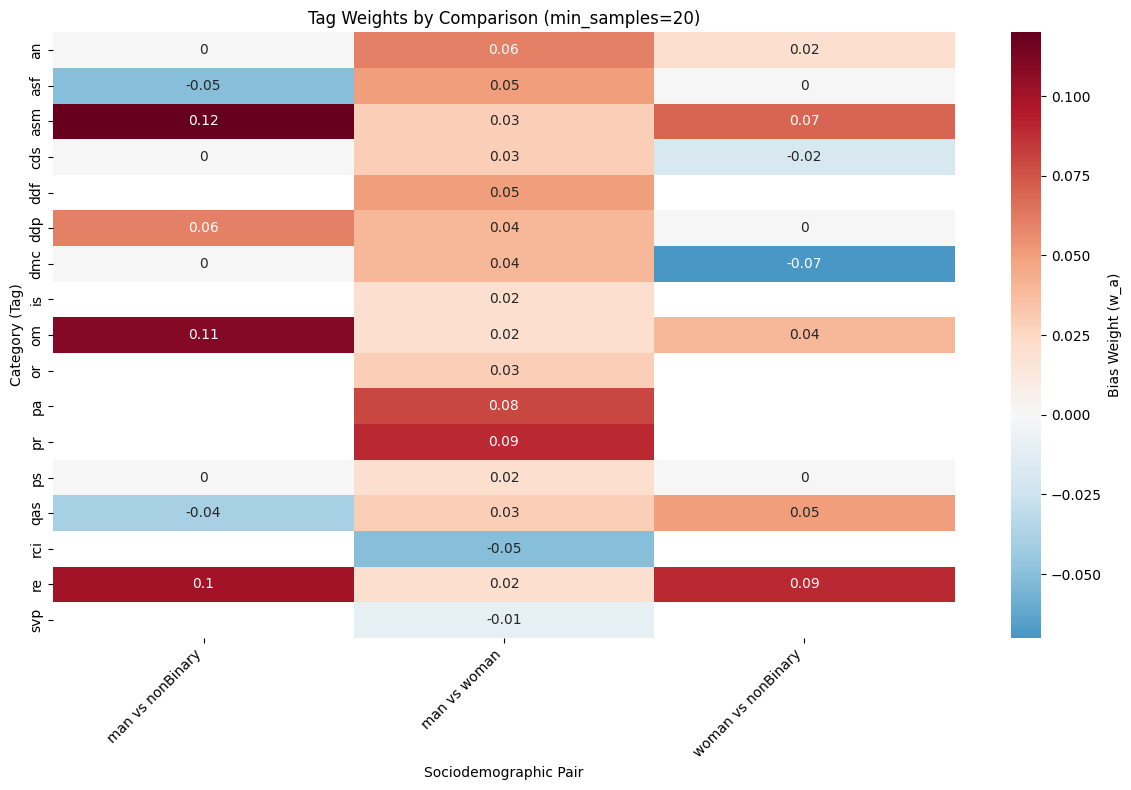

In [14]:
# 1. Calculate the raw results
results = calculate_pairwise_tag_weights(gender_aggregated_df_category, 'gender')

# 2. Filter and plot
filtered_data = plot_tag_weights(results, min_samples=20)

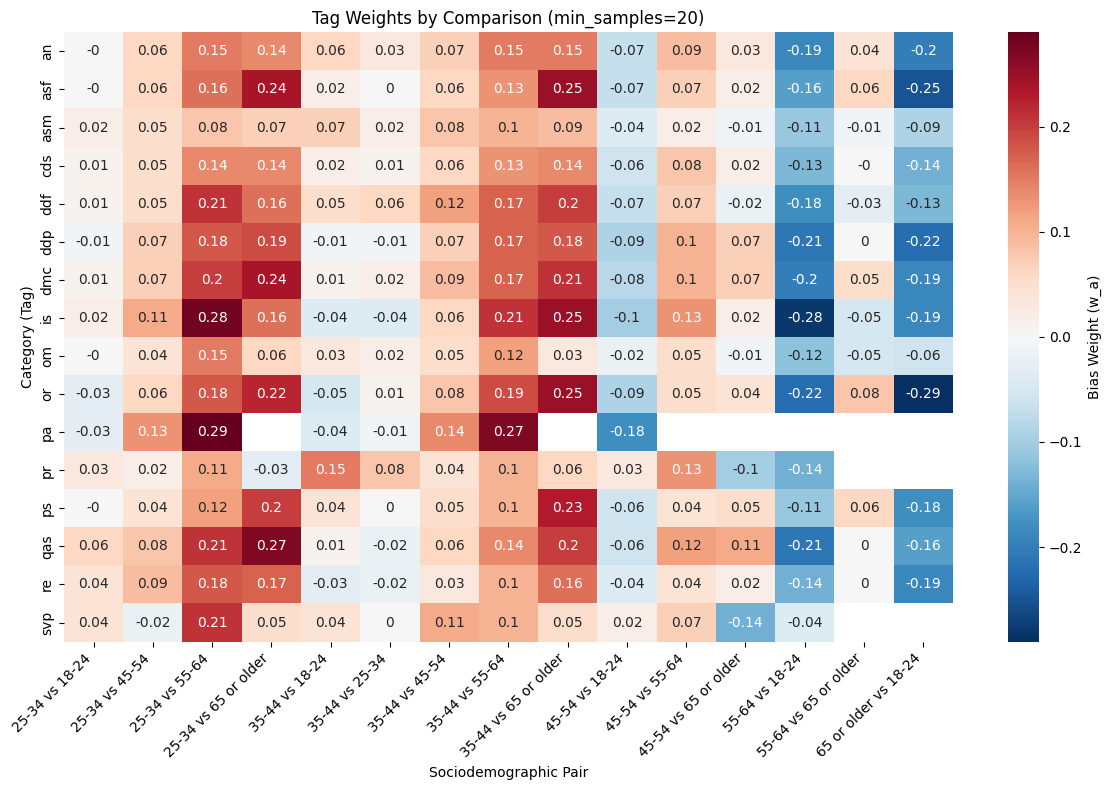

In [10]:
# 1. Calculate the raw results
results = calculate_pairwise_tag_weights(age_aggregated_df_category, 'age')

# 2. Filter and plot
filtered_data = plot_tag_weights(results, min_samples=20)

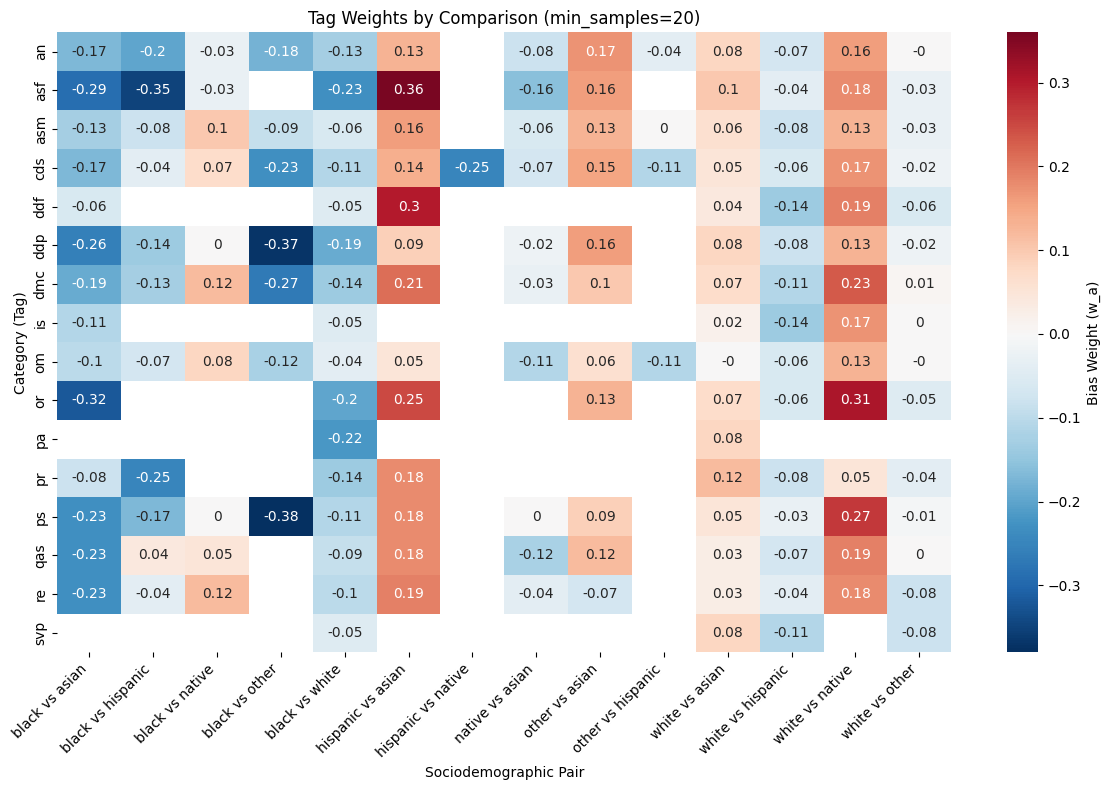

In [148]:
# 1. Calculate the raw results
results = calculate_pairwise_tag_weights(race_aggregated_df_category, 'race')

# 2. Filter and plot
filtered_data = plot_tag_weights(results, min_samples=20)

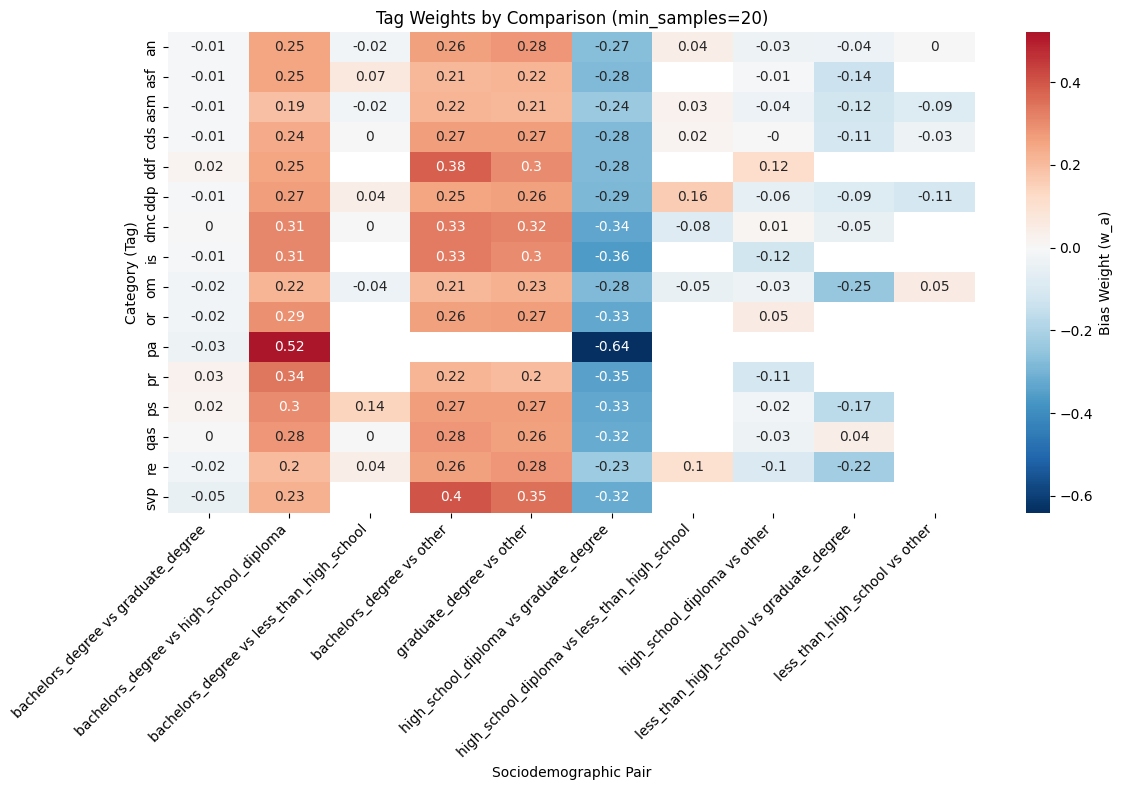

In [149]:
# 1. Calculate the raw results
results = calculate_pairwise_tag_weights(education_aggregated_df_category, 'education')

# 2. Filter and plot
filtered_data = plot_tag_weights(results, min_samples=20)

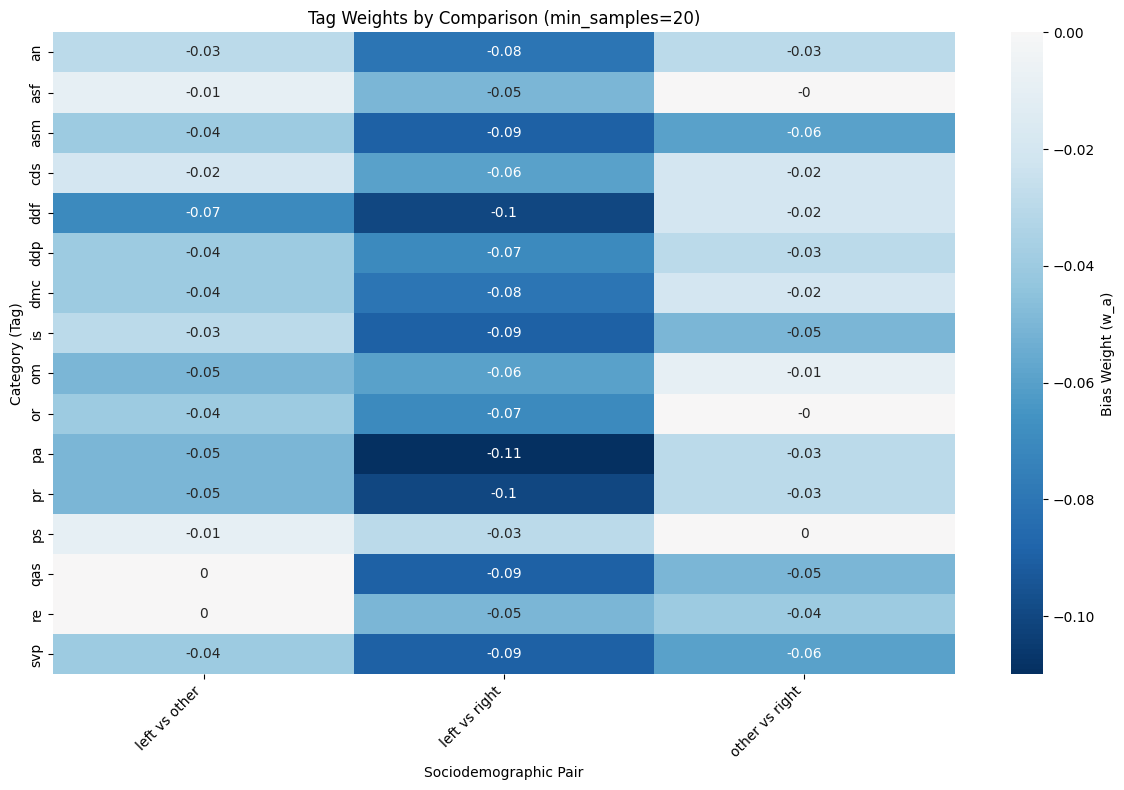

In [11]:
# 1. Calculate the raw results
results = calculate_pairwise_tag_weights(ideology_aggregated_df_category, 'ideology')

# 2. Filter and plot
filtered_data = plot_tag_weights(results, min_samples=20)